In [ ]:
%pip install contextily

In [26]:
import os
from google.colab import userdata
CARTODB_API_KEY = userdata.get('CARTODB_API_KEY')

Zoomed Axis limits: -13469658.385986103 3829123.83702844 -12913060.932019735 4136735.049397425
Using zoom level 9, this will download 45 tiles
Tiles requested at zoom 9: 45


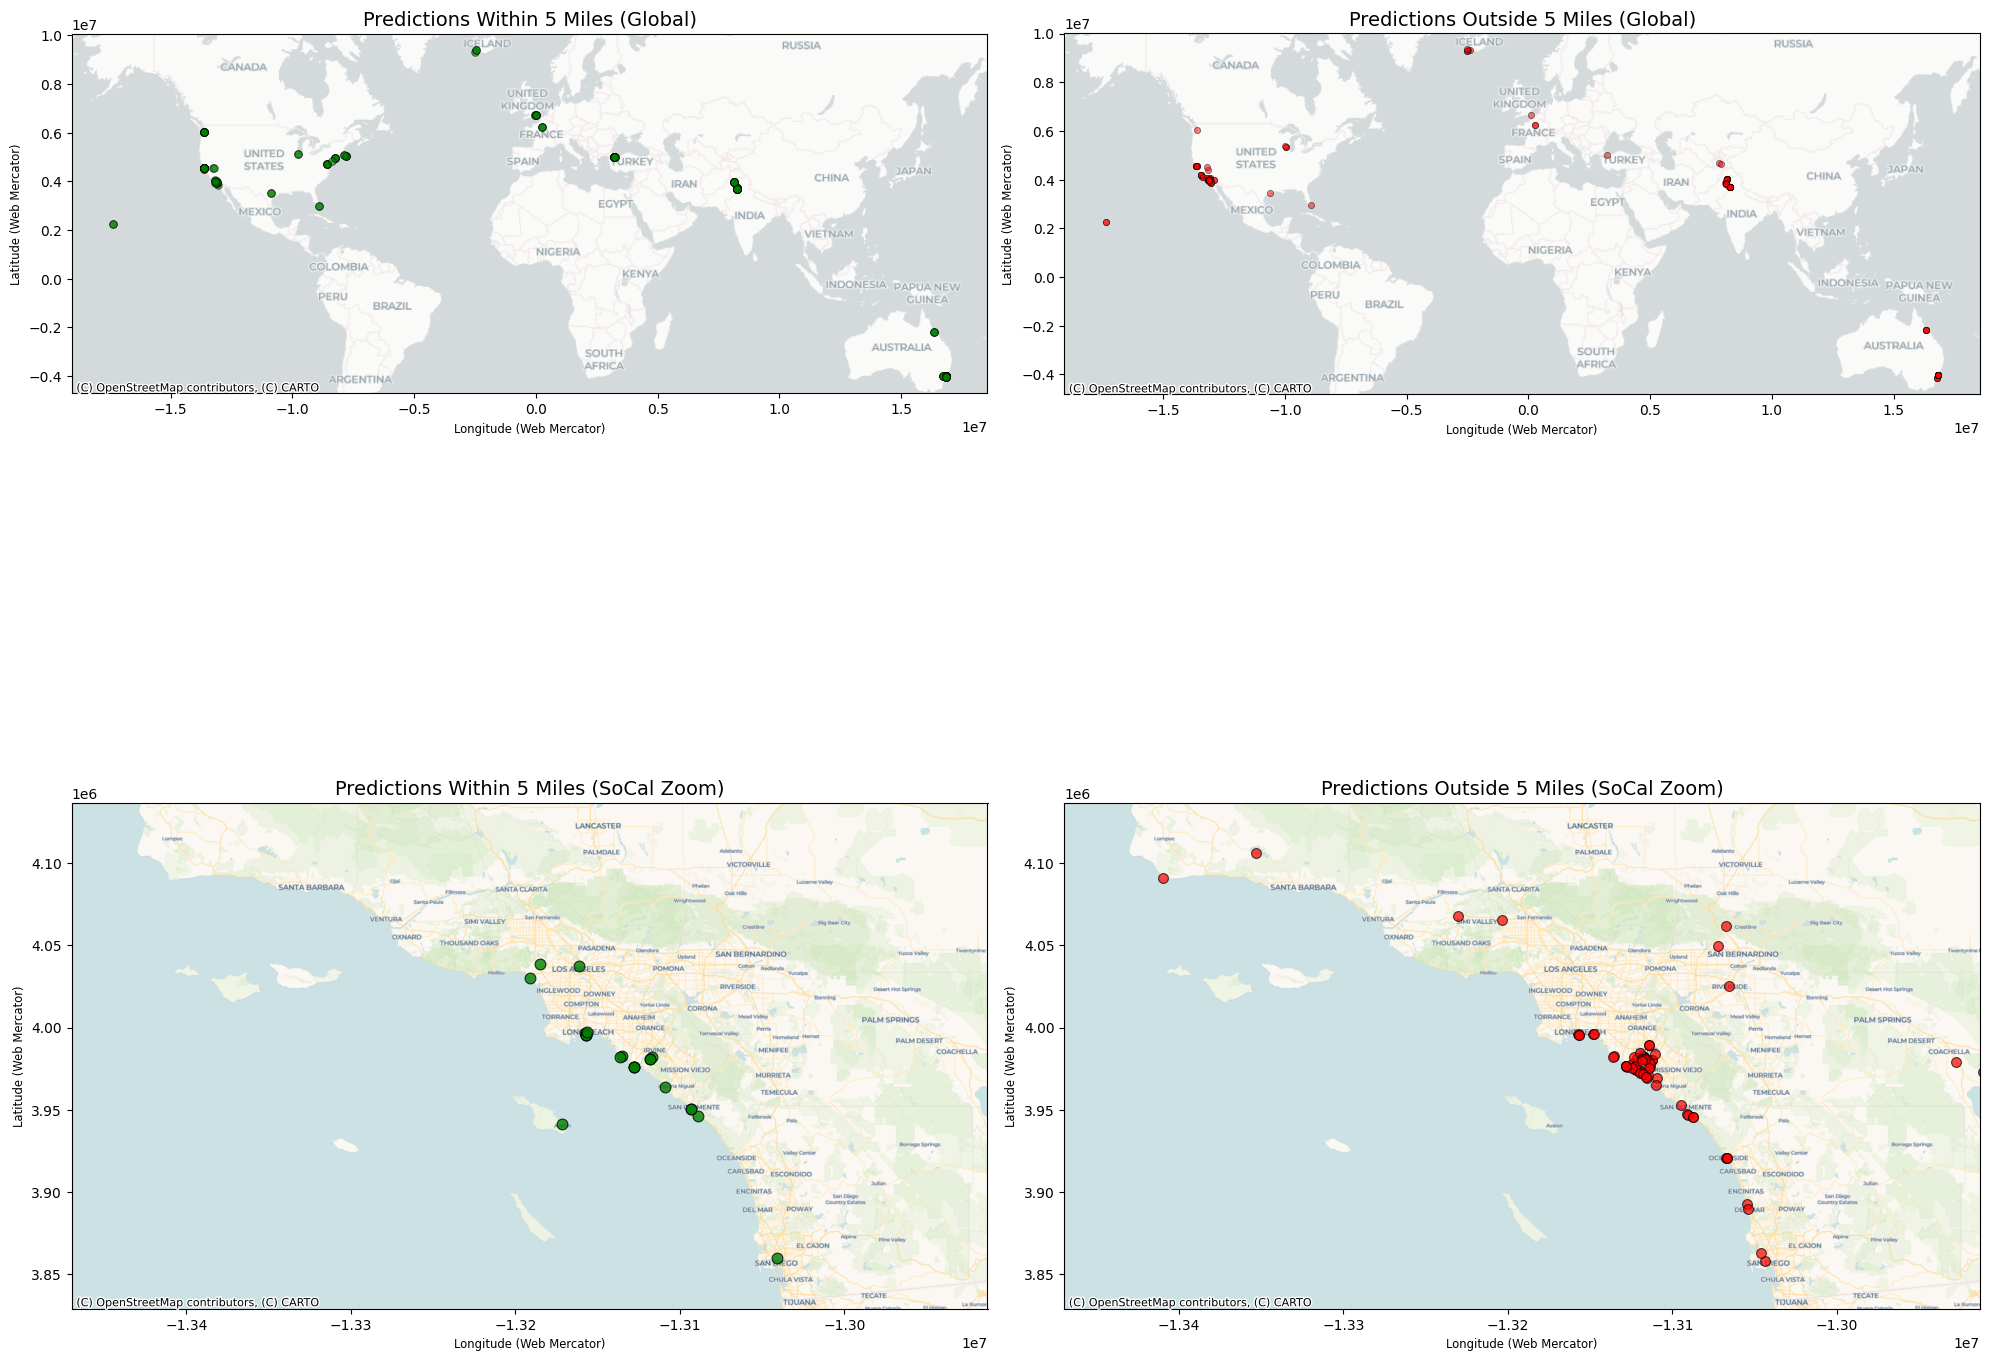

In [27]:
import json
import math
import pandas as pd
import geopandas as gpd
from shapely.geometry import Point
import matplotlib.pyplot as plt
import contextily as cx

def haversine_distance(lat1, lon1, lat2, lon2):
    # Radius of the Earth in miles
    R = 3958.8

    phi1 = math.radians(lat1)
    phi2 = math.radians(lat2)
    delta_phi = math.radians(lat2 - lat1)
    delta_lambda = math.radians(lon2 - lon1)

    a = math.sin(delta_phi / 2.0) ** 2 + \
        math.cos(phi1) * math.cos(phi2) * \
        math.sin(delta_lambda / 2.0) ** 2
    c = 2 * math.atan2(math.sqrt(a), math.sqrt(1 - a))

    return R * c

# Load the JSON data
file_path = "/content/cs117_images_gps.json"
with open(file_path, 'r') as f:
    data = json.load(f)

# Process records and check distance threshold
records = []
for item in data:
    actual = item.get("actual_gps")
    if not actual or "latitude" not in actual or "longitude" not in actual:
        continue

    act_lat = actual["latitude"]
    act_lon = actual["longitude"]

    # Check if any prediction is within 5 miles
    within_5_miles = False
    for pred in item.get("top_5_predictions", []):
        pred_lat = pred.get("latitude")
        pred_lon = pred.get("longitude")
        if pred_lat is not None and pred_lon is not None:
            dist = haversine_distance(act_lat, act_lon, pred_lat, pred_lon)
            if dist <= 5.0:
                within_5_miles = True
                break

    records.append({
        "latitude": act_lat,
        "longitude": act_lon,
        "color": "green" if within_5_miles else "red",
        "status": "Within 5 miles" if within_5_miles else "Outside 5 miles"
    })

df = pd.DataFrame(records)

# Convert to GeoDataFrame
geometry = [Point(xy) for xy in zip(df['longitude'], df['latitude'])]
gdf = gpd.GeoDataFrame(df, geometry=geometry, crs="EPSG:4326")

# Contextily works with Web Mercator (EPSG:3857) projection
gdf_3857 = gdf.to_crs(epsg=3857)

# Define Southern California bounding box in EPSG:4326
socal_bbox = gpd.GeoDataFrame(
    geometry=[Point(-121.0, 32.5), Point(-116.0, 34.8)],
    crs="EPSG:4326"
).to_crs(epsg=3857)

socal_xlim = [socal_bbox.geometry.x.min(), socal_bbox.geometry.x.max()]
socal_ylim = [socal_bbox.geometry.y.min(), socal_bbox.geometry.y.max()]

# Helper to dynamically configure CartoDB providers with user API key if provided
def get_cartodb_provider(style_name, api_key):
    # styles: 'light_all' (Positron), 'rastertiles/voyager' (Voyager)
    provider_dict = {
        "Positron": "light_all",
        "Voyager": "rastertiles/voyager"
    }
    style_path = provider_dict.get(style_name, "light_all")

    # Build standard definition with CartoDB's specific query parameter: ?key=KEY
    if api_key and api_key != "YOUR_CARTODB_API_KEY_HERE":
        url = f"https://basemaps.cartocdn.com/{style_path}/{{z}}/{{x}}/{{y}}.png?key={api_key}"
    else:
        url = f"https://basemaps.cartocdn.com/{style_path}/{{z}}/{{x}}/{{y}}.png"

    return {
        "url": url,
        "attribution": "(C) OpenStreetMap contributors, (C) CARTO"
    }

# Create a 2x2 grid of subplots
fig, axs = plt.subplots(2, 2, figsize=(20, 20))
(ax1, ax2), (ax3, ax4) = axs

# Subset data
green_points = gdf_3857[gdf_3857['color'] == 'green']
red_points = gdf_3857[gdf_3857['color'] == 'red']

# Fetch customized providers incorporating the API key
positron_provider = get_cartodb_provider("Positron", CARTODB_API_KEY)
voyager_provider = get_cartodb_provider("Voyager", CARTODB_API_KEY)

# ---------------- ROW 1: GLOBAL PLOTS ----------------

# Plot 1: Within 5 Miles (Global)
if not green_points.empty:
    green_points.plot(
        ax=ax1,
        color="green",
        markersize=30,
        alpha=0.6,
        edgecolor="black",
        linewidth=0.6,
        zorder=2
    )
cx.add_basemap(
    ax1,
    source=positron_provider["url"],
    attribution=positron_provider["attribution"],
    zorder=1,
    timeout=15,
    headers={"user-agent": "my-geopandas-project/1.0"}
)
ax1.set_title("Predictions Within 5 Miles (Global)", fontsize=14)
ax1.set_xlabel("Longitude (Web Mercator)")
ax1.set_ylabel("Latitude (Web Mercator)")

# Plot 2: Outside 5 Miles (Global)
if not red_points.empty:
    red_points.plot(
        ax=ax2,
        color="red",
        markersize=20,
        alpha=0.5,
        edgecolor="black",
        linewidth=0.6,
        zorder=2
    )
cx.add_basemap(
    ax2,
    source=positron_provider["url"],
    attribution=positron_provider["attribution"],
    zorder=1,
    timeout=15,
    headers={"user-agent": "my-geopandas-project/1.0"}
)
ax2.set_title("Predictions Outside 5 Miles (Global)", fontsize=14)
ax2.set_xlabel("Longitude (Web Mercator)")
ax2.set_ylabel("Latitude (Web Mercator)")

# ---------------- ROW 2: ZOOMED PLOTS (SOUTHERN CALIFORNIA HIGH-RES) ----------------

# Plot 3: Within 5 Miles (SoCal Zoom)
if not green_points.empty:
    green_points.plot(
        ax=ax3,
        color="green",
        markersize=60,
        alpha=0.8,
        edgecolor="black",
        linewidth=0.8,
        zorder=2
    )
# Set bounds FIRST to restrict tile fetch bounds
ax3.set_xlim(socal_xlim)
ax3.set_ylim(socal_ylim)

west, east = ax3.get_xlim()
south, north = ax3.get_ylim()
print("Zoomed Axis limits:", west, south, east, north)
print("Tiles requested at zoom 9:", cx.howmany(west, south, east, north, zoom=9, ll=False))

cx.add_basemap(
    ax3,
    source=voyager_provider["url"],
    attribution=voyager_provider["attribution"],
    zoom=9,
    zorder=1,
    timeout=15,
    headers={"user-agent": "my-geopandas-project/1.0"}
)
ax3.set_title("Predictions Within 5 Miles (SoCal Zoom)", fontsize=14)
ax3.set_xlabel("Longitude (Web Mercator)")
ax3.set_ylabel("Latitude (Web Mercator)")

# Plot 4: Outside 5 Miles (SoCal Zoom)
if not red_points.empty:
    red_points.plot(
        ax=ax4,
        color="red",
        markersize=50,
        alpha=0.7,
        edgecolor="black",
        linewidth=0.8,
        zorder=2
    )
# Set bounds FIRST to restrict tile fetch bounds
ax4.set_xlim(socal_xlim)
ax4.set_ylim(socal_ylim)

cx.add_basemap(
    ax4,
    source=voyager_provider["url"],
    attribution=voyager_provider["attribution"],
    zoom=9,
    zorder=1,
    timeout=15,
    headers={"user-agent": "my-geopandas-project/1.0"}
)
ax4.set_title("Predictions Outside 5 Miles (SoCal Zoom)", fontsize=14)
ax4.set_xlabel("Longitude (Web Mercator)")
ax4.set_ylabel("Latitude (Web Mercator)")

plt.tight_layout()
plt.show()

In [ ]:
from google.colab import files

# Save the figure with 300 DPI for high resolution
high_res_path = "/content/gps_predictions_evaluation_high_res.png"
fig.savefig(high_res_path, dpi=300, bbox_inches='tight')
print(f"Saved high-resolution image to: {high_res_path}")

# Trigger browser download
files.download(high_res_path)